Mounted at /content/drive
Dataset loaded successfully.

First 5 rows of the dataset:


,user,gender,age,how_tall_in_meters,weight,body_mass_index,x1,y1,z1,x2,y2,z2,x3,y3,z3,x4,y4,z4,class
0,debora,Woman,46,1.62,75,28.6,-3,92,-63,-23,18,-19,5,104,-92,-150,-103,-147,sitting
1,debora,Woman,46,1.62,75,28.6,-3,94,-64,-21,18,-18,-14,104,-90,-149,-104,-145,sitting
2,debora,Woman,46,1.62,75,28.6,-1,97,-61,-12,20,-15,-13,104,-90,-151,-104,-144,sitting
3,debora,Woman,46,1.62,75,28.6,-2,96,-57,-15,21,-16,-13,104,-89,-153,-103,-142,sitting
4,debora,Woman,46,1.62,75,28.6,-1,96,-61,-13,20,-15,-13,104,-89,-153,-104,-143,sitting



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165633 entries, 0 to 165632
Data columns (total 19 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user                165633 non-null  object 
 1   gender              165633 non-null  object 
 2   age                 165633 non-null  int64  
 3   how_tall_in_meters  165633 non-null  float64
 4   weight              165633 non-null  int64  
 5   body_mass_index     165633 non-null  float64
 6   x1                  165633 non-null  int64  
 7   y1                  165633 non-null  int64  
 8   z1                  165633 non-null  int64  
 9   x2                  165633 non-null  int64  
 10  y2                  165633 non-null  int64  
 11  z2                  165633 non-null  int64  
 12  x3                  165633 non-null  int64  
 13  y3                  165633 non-null  int64  
 14  z3                  165633 non-null  int64  
 15  x4               

,age,how_tall_in_meters,weight,body_mass_index,x1,y1,z1,x2,y2,z2,x3,y3,z3,x4,y4,z4,gender_Woman
0,46,1.62,75,28.6,-3,92,-63,-23,18,-19,5,104,-92,-150,-103,-147,True
1,46,1.62,75,28.6,-3,94,-64,-21,18,-18,-14,104,-90,-149,-104,-145,True
2,46,1.62,75,28.6,-1,97,-61,-12,20,-15,-13,104,-90,-151,-104,-144,True
3,46,1.62,75,28.6,-2,96,-57,-15,21,-16,-13,104,-89,-153,-103,-142,True
4,46,1.62,75,28.6,-1,96,-61,-13,20,-15,-13,104,-89,-153,-104,-143,True



First 5 rows of target (y):


,class
0,sitting
1,sitting
2,sitting
3,sitting
4,sitting



Shape of features (X): (165633, 17)
Shape of target (y): (165633,)
Applying windowing and extracting statistical features...
Shape of windowed features: (23660, 77)

Starting LOSO Cross-Validation with WINDOWED features (Continuous)...
Processing user: debora
Processing user: jose_carlos
Processing user: katia
Processing user: wallace

--- LOSO Cross-Validation Results (WINDOWED Features Only) ---
Overall F1-score: 0.7498


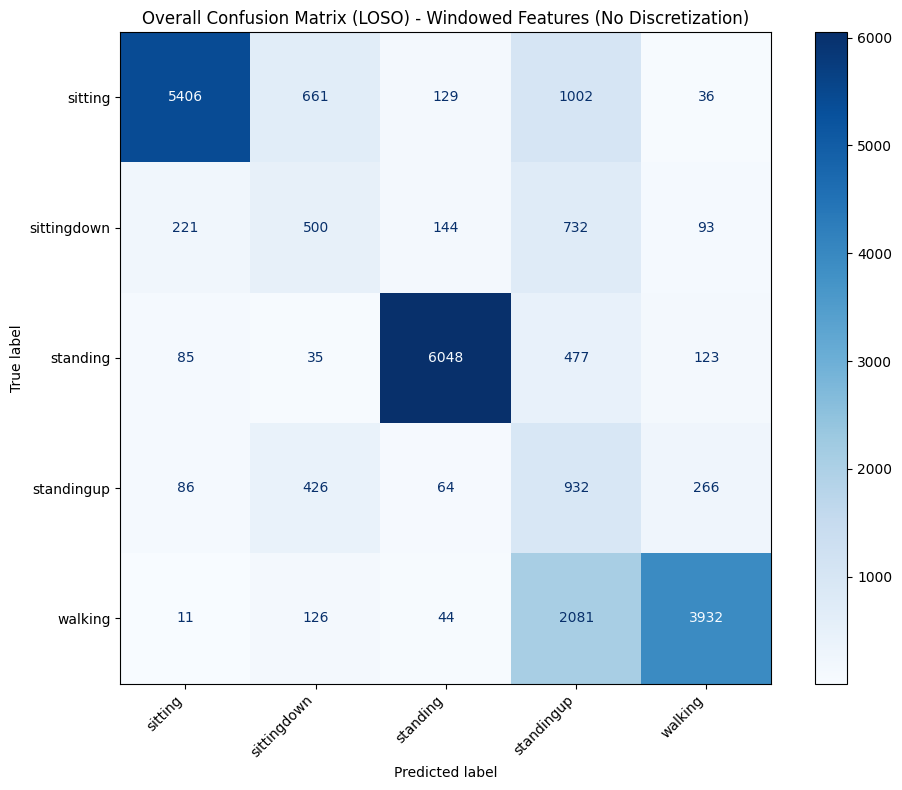

In [1]:
import pandas as pd
from google.colab import drive
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to the dataset
dataset_path = '/content/drive/MyDrive/Colab/baseline.csv'

# Load the dataset
try:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found. Please ensure it exists in your Google Drive.")
    df = None

if df is not None:
    # Display the first 5 rows of the DataFrame
    print("\nFirst 5 rows of the dataset:")
    display(df.head())
    # Display basic information about the DataFrame
    print("\nDataFrame Info:")
    df.info()

# Convert 'gender' column to numerical using one-hot encoding
df = pd.get_dummies(df, columns=['gender'], drop_first=True)

# Define features (X) and target (y)
# Drop 'user' as it will be used for Leave-One-Subject-Out cross-validation, and 'class' is the target.
# We also drop 'gender_Woman' if 'gender' was already encoded (to avoid redundant features if get_dummies created gender_Man and gender_Woman)
# but get_dummies with drop_first=True handles this correctly.

features = df.drop(columns=['user', 'class']).columns
X = df[features]
y = df['class']

# Display the first few rows of the processed features and target
print("\nFirst 5 rows of features (X):")
display(X.head())
print("\nFirst 5 rows of target (y):")
display(y.head())

print(f"\nShape of features (X): {X.shape}")
print(f"Shape of target (y): {y.shape}")

import numpy as np
import pandas as pd
from scipy.stats import iqr
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# --- STEP 1: Windowing and Feature Extraction ---

# Define accelerometer columns to extract statistics from
accel_cols = ['x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4']

# Define other user-specific features that are constant within a user's data
static_features = ['user', 'gender_Woman', 'age', 'how_tall_in_meters', 'weight', 'body_mass_index', 'class']

window_size = 8  # 1 second * 8Hz = 8 rows
overlap = 1      # 150ms overlap
step_size = window_size - overlap

windowed_features_list = []

print("Applying windowing and extracting statistical features...")

# Group by user to ensure windows don't cross user boundaries
for user_id, user_data in df.groupby('user'):
    for i in range(0, len(user_data) - window_size + 1, step_size):
        window = user_data.iloc[i : i + window_size]
        features_dict = {}

        # Add static features
        for col in static_features:
            features_dict[col] = window[col].iloc[0]

        # Extract statistical features
        for col in accel_cols:
            features_dict[f'{col}_mean'] = window[col].mean()
            features_dict[f'{col}_std'] = window[col].std()
            features_dict[f'{col}_min'] = window[col].min()
            features_dict[f'{col}_max'] = window[col].max()
            features_dict[f'{col}_median'] = window[col].median()
            features_dict[f'{col}_iqr'] = iqr(window[col])

        windowed_features_list.append(features_dict)

# Create DataFrame
windowed_df = pd.DataFrame(windowed_features_list)

# Define features (X) and target (y)
# We use X_windowed directly without discretization
features_windowed = [col for col in windowed_df.columns if col not in ['user', 'class']]
X_windowed = windowed_df[features_windowed]
y_windowed = windowed_df['class']

print(f"Shape of windowed features: {X_windowed.shape}")

# --- STEP 2: LOSO Cross-Validation (No Discretization) ---

unique_users_windowed = windowed_df['user'].unique()
f1_scores_per_user_windowed = {}
all_true_labels_windowed = []
all_predictions_windowed = []
overall_cm_windowed = None

print("\nStarting LOSO Cross-Validation with WINDOWED features (Continuous)...")

for user_id in unique_users_windowed:
    print(f"Processing user: {user_id}")

    # Split data based on user_id
    train_indices = windowed_df[windowed_df['user'] != user_id].index
    test_indices = windowed_df[windowed_df['user'] == user_id].index

    X_train_w = X_windowed.loc[train_indices]
    y_train_w = y_windowed.loc[train_indices]
    X_test_w = X_windowed.loc[test_indices]
    y_test_w = y_windowed.loc[test_indices]

    if X_train_w.empty or X_test_w.empty:
        continue

    # Initialize and train Decision Tree
    dt_classifier = DecisionTreeClassifier(random_state=42)
    dt_classifier.fit(X_train_w, y_train_w)

    # Predictions
    y_pred_w = dt_classifier.predict(X_test_w)

    # Metrics
    f1_w = f1_score(y_test_w, y_pred_w, average='weighted')
    f1_scores_per_user_windowed[user_id] = f1_w

    all_true_labels_windowed.extend(y_test_w)
    all_predictions_windowed.extend(y_pred_w)

    # Confusion Matrix aggregation
    cm_fold = confusion_matrix(y_test_w, y_pred_w, labels=dt_classifier.classes_)
    if overall_cm_windowed is None:
        overall_cm_windowed = cm_fold
    else:
        overall_cm_windowed += cm_fold

# --- STEP 3: Results display ---

print("\n--- LOSO Cross-Validation Results (WINDOWED Features Only) ---")
overall_f1_windowed = f1_score(all_true_labels_windowed, all_predictions_windowed, average='weighted')
print(f"Overall F1-score: {overall_f1_windowed:.4f}")

# Display overall confusion matrix
if overall_cm_windowed is not None:
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=overall_cm_windowed, display_labels=dt_classifier.classes_)
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    ax.set_title('Overall Confusion Matrix (LOSO) - Windowed Features (No Discretization)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()